# Sistema de agrupación de casas — California Housing

Objetivo: agrupar las casas según su **región** (`Latitude`, `Longitude`) y su **ingreso medio** (`MedInc`) con un modelo
no supervisado (K-Means) y, después, usar esas etiquetas para entrenar un modelo de clasificación supervisada.

## Paso 1: Carga del conjunto de datos

In [1]:
import os
import pickle

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
DATA_URL = "https://breathecode.herokuapp.com/asset/internal-link?id=809&path=housing.csv"
LOCAL_PATH = "../housing.csv"

# Se usa la copia local si existe; si no, se descarga del enlace del enunciado
total_data = pd.read_csv(LOCAL_PATH if os.path.exists(LOCAL_PATH) else DATA_URL)
os.makedirs("../data/raw", exist_ok=True)
total_data.to_csv("../data/raw/housing.csv", index=False)
total_data.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [2]:
# Solo nos interesan la ubicación y el ingreso medio
FEATURES = ["Latitude", "Longitude", "MedInc"]
data = total_data[FEATURES]
print(data.shape)
print("Nulos:", data.isna().sum().sum())
data.describe()

(20640, 3)
Nulos: 0


,Latitude,Longitude,MedInc
count,20640.000000,20640.000000,20640.000000
mean,35.631861,-119.569704,3.870671
std,2.135952,2.003532,1.899822
min,32.540000,-124.350000,0.499900
25%,33.930000,-121.800000,2.563400
50%,34.260000,-118.490000,3.534800
75%,37.710000,-118.010000,4.743250
max,41.950000,-114.310000,15.000100


No hay valores nulos. Las tres variables tienen rangos de magnitud parecida (latitud ≈ 32–42, longitud ≈ −124 a −114,
ingreso ≈ 0.5–15, en decenas de miles de dólares), así que K-Means puede trabajar directamente con ellas sin escalar
y los centroides quedan en unidades interpretables.

In [3]:
X_train, X_test = train_test_split(data, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (16512, 3) | Test: (4128, 3)


## Paso 2: Construcción del K-Means (6 clusters)

In [4]:
kmeans = KMeans(n_clusters=6, n_init=10, random_state=RANDOM_STATE)
kmeans.fit(X_train)

y_train = kmeans.labels_
print(type(y_train), y_train.dtype, sorted(set(y_train)))

<class 'numpy.ndarray'> int32 [np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5)]


Las etiquetas que devuelve K-Means son enteros `0–5`, pero **no** tienen orden ni magnitud: el cluster 5 no es "mayor"
que el 1. Por eso, al añadirlas al dataset las convertimos a tipo `category`.

In [5]:
X_train = X_train.copy()
X_train["cluster"] = pd.Categorical(y_train)

centroids = pd.DataFrame(kmeans.cluster_centers_, columns=FEATURES).round(2)
centroids["n_casas"] = pd.Series(y_train).value_counts().sort_index()
centroids

,Latitude,Longitude,MedInc,n_casas
0,36.06,-119.72,2.69,1348
1,35.18,-119.53,11.13,342
2,33.82,-117.83,2.89,5628
3,33.86,-118.02,5.59,3024
4,38.35,-121.89,2.82,3919
5,37.70,-121.96,5.51,2251


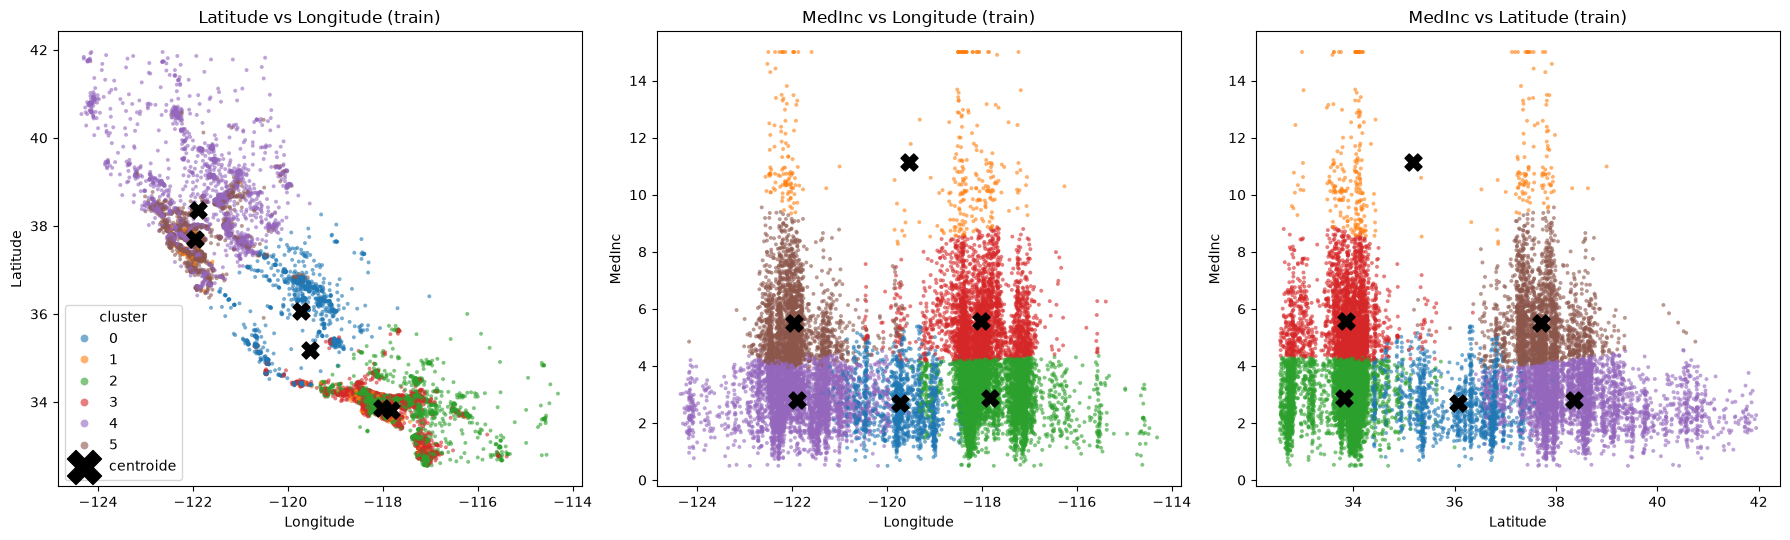

In [6]:
palette = sns.color_palette("tab10", 6)
pairs = [("Longitude", "Latitude"), ("Longitude", "MedInc"), ("Latitude", "MedInc")]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, (x, y) in zip(axes, pairs):
    sns.scatterplot(data=X_train, x=x, y=y, hue="cluster", palette=palette, s=8, alpha=0.6, linewidth=0, ax=ax)
    ax.scatter(centroids[x], centroids[y], c="black", marker="X", s=150, label="centroide")
    ax.set_title(f"{y} vs {x} (train)")
axes[0].legend(title="cluster", markerscale=2, loc="lower left")
for ax in axes[1:]:
    ax.get_legend().remove()
plt.tight_layout()
plt.show()

**Qué se observa**

- En el mapa (longitud vs latitud) aparece la silueta de California y se distinguen con claridad dos grandes zonas:
  el **norte** (Área de la Bahía de San Francisco, Sacramento, Valle Central norte) y el **sur** (Los Ángeles, San Diego).
- Pero los clusters no se separan solo por geografía: los gráficos con `MedInc` muestran que el **ingreso** es el otro
  eje de división. Dentro de cada zona hay un cluster de ingreso bajo y otro de ingreso medio-alto:
  - **Norte**: cluster 4 (ingreso ≈ 2.8) y cluster 5 (ingreso ≈ 5.5, Bahía de San Francisco).
  - **Sur**: cluster 2 (ingreso ≈ 2.9) y cluster 3 (ingreso ≈ 5.6, costa de Los Ángeles / Orange County).
  - Cluster 0: zona interior/central (Valle de San Joaquín, zonas desérticas) con ingreso bajo (≈ 2.7).
  - Cluster 1: grupo pequeño de **ingreso muy alto** (≈ 11) repartido por todo el estado; aquí el ingreso pesa más
    que la ubicación.
- Las fronteras entre clusters son rectas (son celdas de Voronoi alrededor de los centroides), algo que tendremos en
  cuenta al elegir el modelo supervisado.

## Paso 3: Predicción con el conjunto de test

In [7]:
y_test = kmeans.predict(X_test[FEATURES])
X_test = X_test.copy()
X_test["cluster"] = pd.Categorical(y_test)

pd.DataFrame({
    "train (%)": X_train["cluster"].value_counts(normalize=True).sort_index().mul(100).round(1),
    "test (%)": X_test["cluster"].value_counts(normalize=True).sort_index().mul(100).round(1),
})

,train (%),test (%)
cluster,,
0,8.2,8.2
1,2.1,2.2
2,34.1,36.0
3,18.3,17.8
4,23.7,23.2
5,13.6,12.6


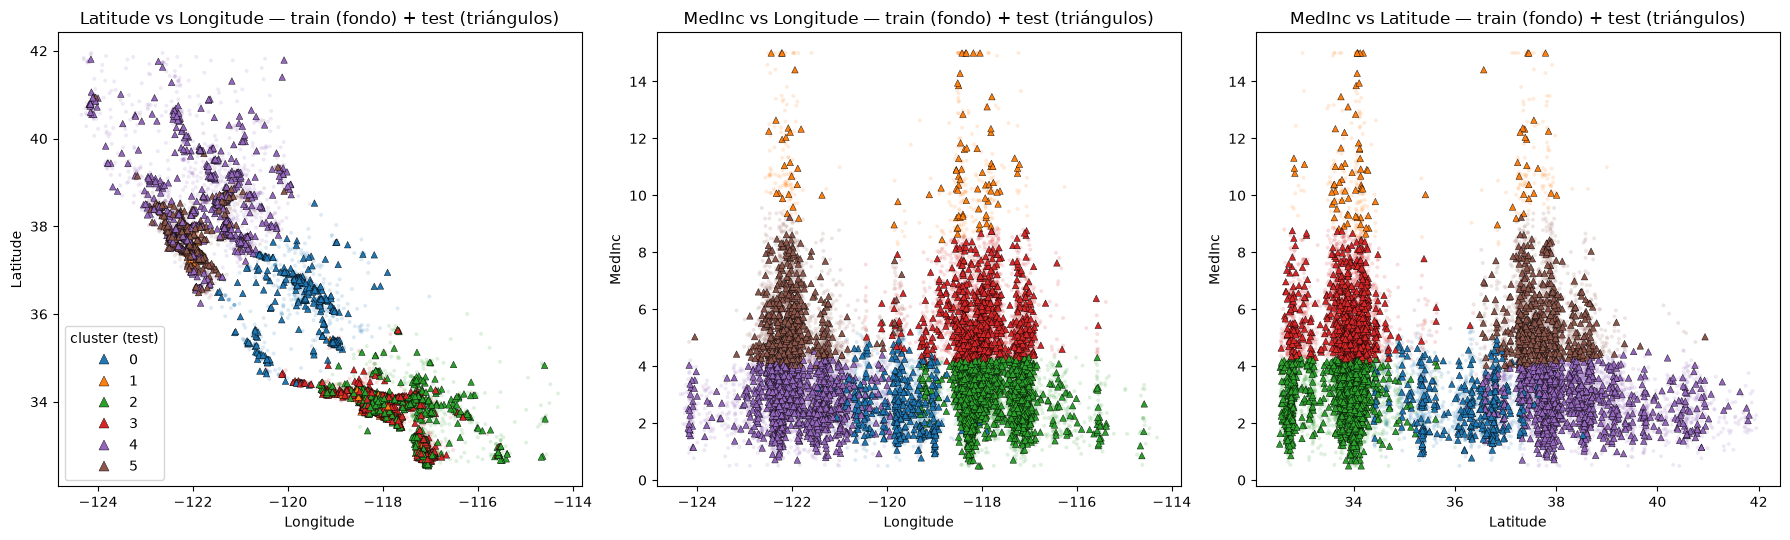

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, (x, y) in zip(axes, pairs):
    sns.scatterplot(data=X_train, x=x, y=y, hue="cluster", palette=palette, s=8, alpha=0.15, linewidth=0, ax=ax,
                    legend=False)
    sns.scatterplot(data=X_test, x=x, y=y, hue="cluster", palette=palette, s=22, marker="^", edgecolor="black",
                    linewidth=0.3, ax=ax)
    ax.set_title(f"{y} vs {x} — train (fondo) + test (triángulos)")
axes[0].legend(title="cluster (test)", markerscale=1.5, loc="lower left")
for ax in axes[1:]:
    ax.get_legend().remove()
plt.tight_layout()
plt.show()

Los puntos de test (triángulos) caen sobre las nubes de train del mismo color y la proporción de casas por cluster es
prácticamente idéntica en ambos conjuntos. La predicción es **satisfactoria**: el K-Means generaliza a puntos nuevos
de forma coherente (era de esperar, ya que asignar un punto nuevo consiste simplemente en buscar su centroide más
cercano).

## Paso 4: Modelo de clasificación supervisada

Ahora las etiquetas de K-Means son nuestro *target*. Comparamos varios candidatos:

- **Regresión logística** (con escalado): las regiones de K-Means están separadas por fronteras lineales, así que un
  modelo lineal multiclase debería poder reproducirlas casi a la perfección.
- **Árbol de decisión**: interpretable, pero aproxima las fronteras oblicuas con "escalones".
- **Random Forest**: más robusto que un único árbol.

In [9]:
y_train = X_train["cluster"]
y_test = X_test["cluster"]
Xtr, Xte = X_train[FEATURES], X_test[FEATURES]

candidates = {
    "LogisticRegression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, C=100)),
    "DecisionTree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "RandomForest": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
}

results = []
for name, model in candidates.items():
    model.fit(Xtr, y_train)
    results.append({
        "modelo": name,
        "accuracy train": accuracy_score(y_train, model.predict(Xtr)),
        "accuracy test": accuracy_score(y_test, model.predict(Xte)),
    })
results = pd.DataFrame(results).set_index("modelo").sort_values("accuracy test", ascending=False).round(4)
results

,accuracy train,accuracy test
modelo,,
LogisticRegression,0.9978,0.9971
RandomForest,1.0000,0.9954
DecisionTree,1.0000,0.9947


In [10]:
best_name = results.index[0]
clf = candidates[best_name]
y_pred = clf.predict(Xte)
print("Mejor modelo:", best_name)
print(classification_report(y_test, y_pred, digits=4))

Mejor modelo: LogisticRegression
              precision    recall  f1-score   support

           0     1.0000    0.9941    0.9970       338
           1     0.9889    1.0000    0.9944        89
           2     0.9967    1.0000    0.9983      1488
           3     1.0000    0.9932    0.9966       736
           4     0.9938    1.0000    0.9969       957
           5     1.0000    0.9904    0.9952       520

    accuracy                         0.9971      4128
   macro avg     0.9966    0.9963    0.9964      4128
weighted avg     0.9971    0.9971    0.9971      4128



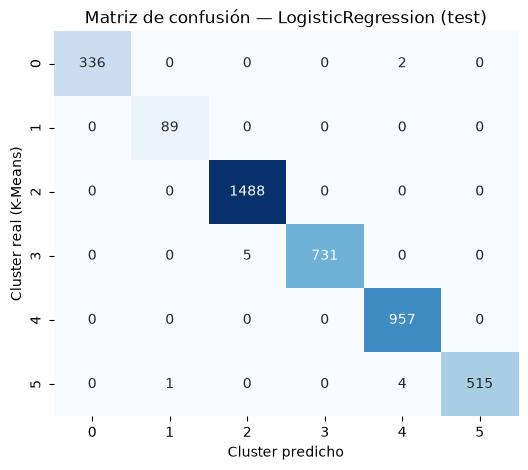

In [11]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.xlabel("Cluster predicho")
plt.ylabel("Cluster real (K-Means)")
plt.title(f"Matriz de confusión — {best_name} (test)")
plt.show()

**Qué se observa**

- Los tres modelos aprenden muy bien la agrupación, pero la **regresión logística** es la que mejor la reproduce:
  como K-Means divide el espacio con fronteras lineales, un clasificador lineal se ajusta exactamente a ese tipo de
  frontera y no sobreajusta (accuracy de train y test prácticamente iguales).
- El árbol y el Random Forest alcanzan el 100 % en train pero bajan algo en test: los pocos errores son casas situadas
  justo en la frontera entre dos clusters, que los árboles aproximan con cortes paralelos a los ejes.
- En la matriz de confusión casi toda la masa está en la diagonal; los escasos fallos se dan entre clusters vecinos
  (p. ej. ingreso bajo/medio de una misma zona).
- Ventaja práctica: el clasificador permite etiquetar casas nuevas sin volver a ejecutar K-Means, y sus coeficientes
  nos dicen qué variables separan cada grupo.

## Paso 5: Guardado de los modelos

In [12]:
os.makedirs("../models", exist_ok=True)
with open("../models/kmeans_6_clusters_42.sav", "wb") as f:
    pickle.dump(kmeans, f)
with open(f"../models/{best_name.lower()}_classifier_42.sav", "wb") as f:
    pickle.dump(clf, f)

os.makedirs("../data/processed", exist_ok=True)
X_train.to_csv("../data/processed/clean_train.csv", index=False)
X_test.to_csv("../data/processed/clean_test.csv", index=False)
sorted(os.listdir("../models"))

['.gitkeep',
 'kmeans_6_clusters_42.sav',
 'logisticregression_classifier_42.sav']